# 02 · Data Quality Report (EDA item 1)
**CRISP-DM Phase 2 — Data Understanding: *Verify data quality***

We check the data-quality dimensions that matter for a price series:

* **Completeness:** are all hours present?
* **Uniqueness:** are there duplicate timestamps?
* **Validity:** are prices positive, and is `low ≤ open, close ≤ high`?
* **Consistency:** are there zero-volume candles?
* **Outliers:** are there extreme moves, and are they errors or real events?

We then apply the **gap policy** agreed in Business Understanding and produce the cleaned `interim` datasets.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.data.clean import fill_gaps, find_gaps, flag_outliers, quality_report, robust_zscore
from src.data.collect import load_raw
from src.features.returns import log_returns, resample_ohlcv
from src.visualization.style import BLUE, NEUTRAL, ORANGE, TEXT_SECONDARY, apply_style, save

apply_style()
raw = load_raw()

In [3]:
report = quality_report(raw)
pd.Series(report, name="value").to_frame()

,value
rows,79836.0000
expected_rows,79964.0000
missing_rows,128.0000
completeness_pct,99.8399
duplicate_timestamps,0.0000
null_values,0.0000
non_positive_prices,0.0000
ohlc_violations,0.0000
zero_volume_candles,4.0000
n_gaps,28.0000


**Reading the report**

* No duplicate timestamps, no non-positive prices and no OHLC violations. The **validity** and **uniqueness** dimensions pass.
* **Completeness** is ~99.84%. A small number of hours are missing, and they are grouped into a few dozen gaps.
* A handful of candles have zero volume: hours where the exchange was up but nothing traded.

## The gaps in detail

In [4]:
gaps = find_gaps(raw)
gaps.sort_values("missing_candles", ascending=False).head(12)

,gap_start,gap_end,missing_candles
2,2018-02-08 01:00:00+00:00,2018-02-09 09:00:00+00:00,33
3,2018-06-26 02:00:00+00:00,2018-06-26 11:00:00+00:00,10
9,2019-05-15 03:00:00+00:00,2019-05-15 12:00:00+00:00,10
10,2019-08-15 02:00:00+00:00,2019-08-15 09:00:00+00:00,8
5,2018-07-04 01:00:00+00:00,2018-07-04 07:00:00+00:00,7
7,2018-11-14 02:00:00+00:00,2018-11-14 08:00:00+00:00,7
0,2017-09-06 17:00:00+00:00,2017-09-06 22:00:00+00:00,6
8,2019-03-12 02:00:00+00:00,2019-03-12 07:00:00+00:00,6
14,2020-02-19 12:00:00+00:00,2020-02-19 16:00:00+00:00,5
25,2021-08-13 02:00:00+00:00,2021-08-13 05:00:00+00:00,4


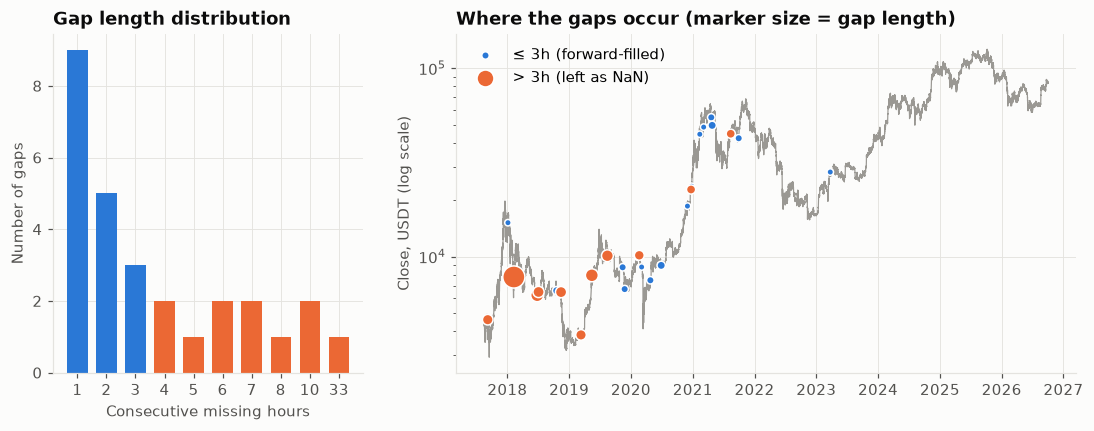

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})

counts = gaps["missing_candles"].value_counts().sort_index()
colors = [BLUE if n <= config.MAX_FFILL_GAP_HOURS else ORANGE for n in counts.index]
ax1.bar(counts.index.astype(str), counts.values, color=colors, width=0.7)
ax1.set(title="Gap length distribution", xlabel="Consecutive missing hours", ylabel="Number of gaps")

ax2.plot(raw.index, raw["close"], color=NEUTRAL, linewidth=0.8)
ax2.set_yscale("log")
short = gaps[gaps["missing_candles"] <= config.MAX_FFILL_GAP_HOURS]
long_ = gaps[gaps["missing_candles"] > config.MAX_FFILL_GAP_HOURS]
for subset, color, label in [(short, BLUE, f"≤ {config.MAX_FFILL_GAP_HOURS}h (forward-filled)"),
                             (long_, ORANGE, f"> {config.MAX_FFILL_GAP_HOURS}h (left as NaN)")]:
    ax2.scatter(subset["gap_start"], raw["close"].asof(subset["gap_start"]),
                s=12 + 6 * subset["missing_candles"], color=color, label=label, zorder=3,
                edgecolor="white", linewidth=1)
ax2.set(title="Where the gaps occur (marker size = gap length)", ylabel="Close, USDT (log scale)")
ax2.legend(loc="upper left")
save(fig, "02_gaps")
plt.show()

**Interpretation**

* The 28 gaps cluster in **2018–2021**, with only one in 2017 and one in 2023. **22 of them start between 01:00 and 07:00 UTC, and 13 at exactly 02:00.** A fixed low-traffic time slot points strongly to **scheduled exchange maintenance**, not data errors.
* The longest outage is **33 hours, on 8–9 February 2018**.
* **Type of missingness:** the exchange being offline does not depend on the price, so the gaps are close to **MCAR (Missing Completely At Random)**. Removing or filling them will not bias the return distribution.
* **The policy is confirmed.** Most gaps are 1–3 hours, so forward-filling them barely changes anything. The few long gaps (up to 33h) would create a fake flat period if filled, so they stay NaN.

## Zero-volume candles

In [6]:
raw[raw["volume"] == 0][["open", "high", "low", "close", "volume", "number_of_trades"]]

,open,high,low,close,volume,number_of_trades
open_time,,,,,,
2017-09-06 16:00:00+00:00,4619.43,4619.43,4619.43,4619.43,0.0,0
2019-06-07 21:00:00+00:00,7930.85,7930.85,7930.85,7930.85,0.0,0
2021-02-11 03:00:00+00:00,44582.07,44582.07,44582.07,44582.07,0.0,0
2023-03-24 12:00:00+00:00,28080.00,28080.00,28080.00,28080.00,0.0,0


These hours have `O = H = L = C` and no trades. They are valid observations ("nothing happened") rather than errors, so we keep them.
`taker_buy_ratio` is undefined for them (0/0), and `src.features.returns.taker_buy_ratio` returns NaN in that case.

## Apply the gap policy

In [7]:
clean_1h = fill_gaps(raw)

summary = pd.Series({
    "rows on full hourly grid": len(clean_1h),
    "originally missing": int(clean_1h["is_missing"].sum()),
    "forward-filled (short gaps)": int(clean_1h["filled"].sum()),
    "left NaN (long gaps)": int(clean_1h["close"].isna().sum()),
})
summary.to_frame("hours")

,hours
rows on full hourly grid,79964
originally missing,128
forward-filled (short gaps),28
left NaN (long gaps),100


## Resample to 4h and 1D

Buckets are aligned to UTC (`00:00, 04:00, …`). A bucket that contains any **unfilled** hour is marked incomplete and set to NaN. Otherwise a long outage would produce a fake candle built from partial data.

In [8]:
frames = {"1h": clean_1h}
for rule in config.RESAMPLE_INTERVALS:
    frames[rule] = resample_ohlcv(clean_1h, rule)

pd.DataFrame({
    rule: {"candles": len(df), "incomplete (NaN)": int(df["close"].isna().sum())}
    for rule, df in frames.items()
}).T

,candles,incomplete (NaN)
1h,79964,100
4h,19991,34
1D,3332,13


## Outliers (EDA item 5)

Raw prices cannot be judged for outliers directly: they trend over a 30× range, so "extreme" only makes
sense for **changes**. We screen the **daily log return** and the **daily high–low range** (the
granularity the model uses).

Returns are fat-tailed (`03_eda.ipynb`, item 4), so a classic mean/std z-score is distorted by the very
points it is trying to find. We use a **robust z-score** instead: distance from the median in units of
the scaled MAD (median absolute deviation), flagged at |z| > 5 (`config.OUTLIER_Z`).

In [9]:
daily = frames["1D"]
candidates = pd.DataFrame({
    "return": log_returns(daily["close"]),
    "hl_range": np.log(daily["high"] / daily["low"]),
}).dropna()
flags = candidates.apply(flag_outliers)

pd.DataFrame({"flagged days": flags.sum(), "% of days": 100 * flags.mean()}).style.format({"% of days": "{:.2f}"})

,flagged days,% of days
return,49,1.48
hl_range,78,2.36


In [10]:
z = robust_zscore(candidates["return"])
top = z[flags["return"]].abs().sort_values(ascending=False).head(10).index
pd.DataFrame({
    "daily move": np.expm1(candidates.loc[top, "return"]),
    "robust z": z[top],
}).style.format({"daily move": "{:+.1%}", "robust z": "{:+.1f}"})

,daily move,robust z
open_time,,
2020-03-12 00:00:00+00:00,-39.5%,-23.2
2018-01-16 00:00:00+00:00,-19.5%,-10.0
2017-09-14 00:00:00+00:00,-19.2%,-9.8
2017-12-07 00:00:00+00:00,+22.5%,+9.3
2021-02-08 00:00:00+00:00,+19.5%,+8.2
2022-06-13 00:00:00+00:00,-15.4%,-7.7
2018-02-05 00:00:00+00:00,-15.2%,-7.6
2019-04-02 00:00:00+00:00,+17.2%,+7.3
2021-05-19 00:00:00+00:00,-14.4%,-7.2


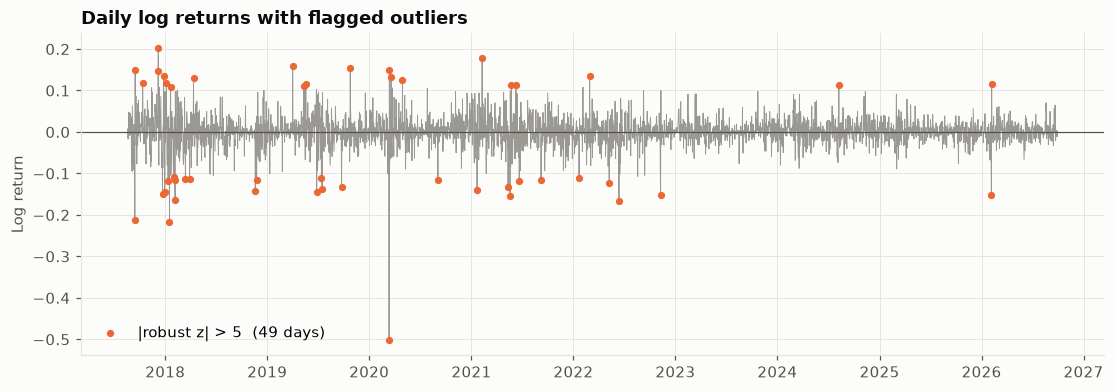

In [11]:
fig, ax = plt.subplots(figsize=(12, 3.8))
r = candidates["return"]
ax.plot(r.index, r, color=NEUTRAL, linewidth=0.6)
ax.scatter(r.index[flags["return"]], r[flags["return"]], s=14, color=ORANGE, zorder=3,
           label=f"|robust z| > {config.OUTLIER_Z:g}  ({flags['return'].sum()} days)")
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set(title="Daily log returns with flagged outliers", ylabel="Log return")
ax.legend(loc="lower left")
save(fig, "02_outliers")
plt.show()

**Are they errors?** No. Every flagged day passes the validity checks above (positive prices, consistent
OHLC), and the largest ones line up with documented market events:

| Date | Move | Event |
|---|---|---|
| 2020-03-12 | −39.5% | COVID-19 market crash ("Black Thursday") |
| 2017-12-07 | +22.5% | Peak of the 2017 bull run, CME/CBOE futures launch week |
| 2021-02-08 | +19.5% | Tesla announces a $1.5B Bitcoin purchase |
| 2017-09-14 | −19.2% | Chinese regulators order exchanges to close |
| 2022-06-13 | −15.4% | Celsius freezes withdrawals |
| 2022-11-09 | −14.1% | FTX collapse |

**What would removing them change?** The table below compares the daily returns with the outliers kept
(our choice) and dropped. This is the before/after check for the decision.

In [12]:
def tail_stats(x: pd.Series) -> dict:
    return {"days": len(x), "std %": 100 * x.std(), "excess kurtosis": x.kurt(),
            "worst day %": 100 * np.expm1(x.min()), "best day %": 100 * np.expm1(x.max())}

pd.DataFrame({
    "kept (applied)": tail_stats(r),
    "dropped (rejected option)": tail_stats(r[~flags["return"]]),
}).style.format("{:,.2f}")

,kept (applied),dropped (rejected option)
days,"3,307.00","3,258.00"
std %,3.53,3.00
excess kurtosis,16.15,1.72
worst day %,-39.50,-10.16
best day %,22.50,11.42


**Decision: keep every outlier (0 rows removed), and make the pipeline robust to them instead.**

* They are **real, tradable events**, not measurement errors. Removing them would hide exactly the crashes a
  portfolio strategy must survive and make any backtest look safer than reality: dropping them cuts the
  measured volatility and removes most of the excess kurtosis shown above.
* The rest of the pipeline is already designed to limit their influence:
  * features are **returns and ratios**, so one crash does not shift a whole price level;
  * the target is a **3-class label**, so a −39% day counts as one "down" sample, exactly like a −2% day;
    it cannot dominate a loss the way it would in regression;
  * the EDA uses **rank-based statistics** (Spearman, Mann–Whitney) next to the classic ones;
  * tree models split on order, not magnitude; the linear model is standardized inside its pipeline.
* The 1h data is not screened separately: the model works on daily candles, and the hourly extremes
  are the same events seen at a finer scale.

In [13]:
config.INTERIM_DIR.mkdir(parents=True, exist_ok=True)
for rule, df in frames.items():
    path = config.INTERIM_DIR / f"{config.SYMBOL.lower()}_{rule}_clean.parquet"
    df.to_parquet(path)
    print(f"saved {path.relative_to(ROOT)}  ({len(df):,} rows)")

saved data/interim/btcusdt_1h_clean.parquet  (79,964 rows)
saved data/interim/btcusdt_4h_clean.parquet  (19,991 rows)
saved data/interim/btcusdt_1D_clean.parquet  (3,332 rows)


## Quality conclusions

| Dimension | Result |
|---|---|
| Completeness | 99.84%: 128 missing hours in 28 gaps, mostly 2018–2021 maintenance windows |
| Uniqueness | No duplicate timestamps |
| Validity | No non-positive prices, no OHLC violations |
| Consistency | A few zero-volume candles: kept, and flagged through a NaN `taker_buy_ratio` |
| Outliers | 49 extreme daily returns (robust z-score above 5): verified as real market events and kept |
| Action | Gaps ≤ 3h forward-filled and flagged (`filled`). Longer gaps left NaN. Incomplete 4h/1D buckets set to NaN. |

The data is trustworthy enough for EDA. The `interim/` files are regenerated by this notebook and are not committed to Git.